# 02 — GMM de livros

Agrupa os livros em perfis de gênero/estilo com um **Gaussian Mixture Model**. Cada livro recebe uma probabilidade de pertencer a cada componente (`predict_proba`), usada depois como perfil do livro e para montar o perfil do usuário.

Entrada: `books_df.parquet` (gerado ao fim de `clustering_model.ipynb`). Saídas: `book_probs.parquet`, `book_vectors.parquet`, `book_meta.parquet`, `gmm_books.joblib`.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler

from recsys import book_features

SEED = 0
GENRES = ['fiction', 'history, historical fiction, biography', 'fantasy, paranormal',
          'mystery, thriller, crime', 'poetry', 'romance', 'non-fiction', 'children',
          'young-adult', 'comics, graphic']
books_df = pd.read_parquet('books_df.parquet')
print(books_df.shape)

(2360655, 29)


### Features

`book_features` limpa os problemas listados em `Data_Understanding.md` (gêneros negativos, anos e páginas inválidos, nulos com flag de ausência) e devolve gêneros em **proporção**. O GMM usa só variáveis contínuas (assume componentes gaussianos); as flags binárias ficam apenas para a rede neural.

In [2]:
feat = book_features(books_df, GENRES)
feat.index = books_df['book_id'].to_numpy()
GMM_COLS = ['log_ratings', 'average_rating', 'log_pages', 'decade'] + [c for c in feat.columns if c.startswith('g_')]
print(feat.isna().sum().sum(), 'NaN;', len(GMM_COLS), 'features no GMM')
feat[GMM_COLS].describe().T.round(2)

0 NaN; 14 features no GMM


,count,mean,std,min,25%,50%,75%,max
log_ratings,2360655.0,3.27,1.81,0.00,1.95,3.04,4.36,15.40
average_rating,2360655.0,3.87,0.54,0.00,3.63,3.91,4.16,5.00
log_pages,2360655.0,5.37,0.71,0.69,5.30,5.51,5.68,8.52
decade,2360655.0,2004.43,12.56,1400.00,2000.00,2010.00,2010.00,2020.00
g_fiction,2360655.0,0.19,0.29,0.00,0.00,0.02,0.27,1.00
"g_history, historical fiction, biography",2360655.0,0.09,0.20,0.00,0.00,0.00,0.03,1.00
"g_fantasy, paranormal",2360655.0,0.08,0.20,0.00,0.00,0.00,0.00,1.00
"g_mystery, thriller, crime",2360655.0,0.08,0.21,0.00,0.00,0.00,0.00,1.00
g_poetry,2360655.0,0.02,0.12,0.00,0.00,0.00,0.00,1.00
g_romance,2360655.0,0.12,0.27,0.00,0.00,0.00,0.02,1.00


### Treino: livros com `ratings_count >= 10`

Abaixo disso a nota média é instável. O ajuste usa ~200 mil livros; a busca de k usa 50 mil para ser rápida. Depois, `predict_proba` é aplicado a **todos** os livros (inclusive os pouco avaliados).

In [3]:
trainable = books_df['ratings_count'].fillna(0).to_numpy() >= 10
print(f'{trainable.sum():,} livros elegíveis de {len(books_df):,}')
rng = np.random.default_rng(SEED)
idx = rng.choice(np.flatnonzero(trainable), size=min(200_000, trainable.sum()), replace=False)

X_all = feat[GMM_COLS].to_numpy(dtype=float)
scaler = StandardScaler().fit(X_all[idx])
pca = PCA(n_components=0.90, random_state=SEED).fit(scaler.transform(X_all[idx]))
Z = pca.transform(scaler.transform(X_all[idx]))
print('componentes PCA:', pca.n_components_, '| variância explicada:', pca.explained_variance_ratio_.sum().round(3))

1,543,759 livros elegíveis de 2,360,655


componentes PCA: 12 | variância explicada: 0.951


### Escolha de k por BIC (e tipo de covariância)

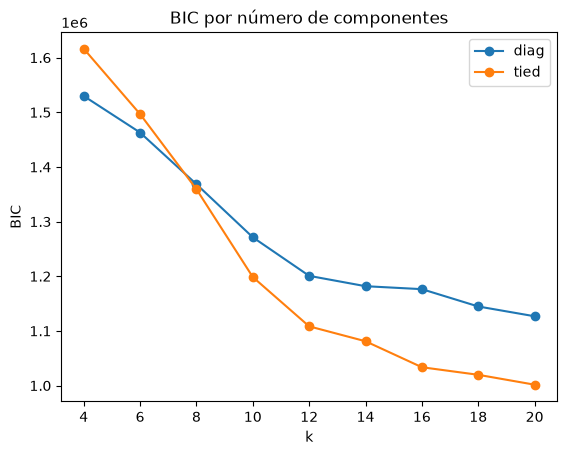

cov,diag,tied
k,,
4,1529862.0,1616382.0
6,1462967.0,1496718.0
8,1368421.0,1359304.0
10,1271302.0,1198554.0
12,1200731.0,1108345.0
14,1181813.0,1081074.0
16,1176408.0,1033550.0
18,1144714.0,1019703.0
20,1126803.0,1001596.0


In [4]:
Zs = Z[:50_000]
rows = []
for cov in ['diag', 'tied']:
    for k in range(4, 21, 2):
        g = GaussianMixture(k, covariance_type=cov, random_state=SEED, max_iter=200).fit(Zs)
        rows.append((cov, k, g.bic(Zs), g.converged_))
bic = pd.DataFrame(rows, columns=['cov', 'k', 'bic', 'convergiu'])
for cov, d in bic.groupby('cov'):
    plt.plot(d['k'], d['bic'], marker='o', label=cov)
plt.xlabel('k'); plt.ylabel('BIC'); plt.legend(); plt.title('BIC por número de componentes'); plt.show()
bic.pivot(index='k', columns='cov', values='bic').round(0)

In [5]:
best = bic.loc[bic['bic'].idxmin()]
COV, K = best['cov'], int(best['k'])
print('menor BIC:', COV, K)

menor BIC: tied 20


**Decisão sobre k.** O BIC diminui de forma quase monótona e a covariância `tied` supera a `diag` a partir de k=8; o mínimo cai na borda da busca (k=20), ou seja, **não há cotovelo nítido** (comum em amostras grandes, onde o BIC sempre premia mais componentes). Mantemos **k=20 com covariância `tied`** como teto de interpretabilidade: os componentes resultantes têm perfis distintos de gênero, páginas, ano e nota (tabela abaixo), incluindo grupos de nicho (livros antigos, quadrinhos, livros pouco avaliados e mal avaliados). Limitação a declarar no artigo: k é escolhido pelo teto da busca, não por um ótimo.

In [6]:
gmm = GaussianMixture(K, covariance_type=COV, random_state=SEED, max_iter=300, n_init=2).fit(Z)
print('convergiu:', gmm.converged_, '| iterações:', gmm.n_iter_)

probs = np.vstack([gmm.predict_proba(pca.transform(scaler.transform(X_all[i:i + 200_000])))
                   for i in range(0, len(X_all), 200_000)]).astype('float32')
assert not np.isnan(probs).any() and np.allclose(probs.sum(1), 1, atol=1e-4)
cols = [f'p_{i}' for i in range(K)]
book_probs = pd.DataFrame(probs, index=pd.Index(books_df['book_id'].to_numpy(), name='book_id'), columns=cols)
book_probs.shape

convergiu: True | iterações: 31


(2360655, 20)

### Perfil dos componentes

In [7]:
hard = book_probs.to_numpy().argmax(1)
tmp = feat.assign(cluster=hard, ratings_count=books_df['ratings_count'].to_numpy(),
                  pages=books_df['num_pages'].where(books_df['num_pages'].between(1, 5000)).to_numpy(),
                  year=books_df['publication_year'].where(books_df['publication_year'].between(1400, 2026)).to_numpy())
gcols = [c for c in feat.columns if c.startswith('g_')]
prof = tmp.groupby('cluster').agg(livros=('cluster', 'size'), nota=('average_rating', 'mean'),
                                  mediana_ratings=('ratings_count', 'median'), paginas=('pages', 'median'), ano=('year', 'median'))
prof['generos_dominantes'] = tmp.groupby('cluster')[gcols].mean().apply(
    lambda r: ', '.join(f'{c[2:]} ({v:.0%})' for c, v in r.nlargest(3).items()), axis=1)
prof.round(2)

,livros,nota,mediana_ratings,paginas,ano,generos_dominantes
cluster,,,,,,
0,128112,3.90,30.0,260.0,2009.0,"non-fiction (57%), history, historical fiction..."
1,278948,3.78,28.0,270.0,2009.0,"fiction (86%), fantasy, paranormal (4%), histo..."
2,53098,3.87,36.0,281.0,2012.0,"romance (55%), fiction (31%), mystery, thrille..."
3,265,3.71,7.0,145.5,1431.0,"non-fiction (13%), history, historical fiction..."
4,90884,3.88,32.0,160.0,2011.0,"comics, graphic (80%), fiction (6%), fantasy, ..."
5,41666,4.05,15.0,112.0,2008.0,"poetry (89%), fiction (4%), non-fiction (3%)"
6,135171,3.83,28.0,312.0,2011.0,"mystery, thriller, crime (83%), fiction (15%),..."
7,114486,2.75,3.0,190.0,2010.0,"non-fiction (4%), fiction (2%), mystery, thril..."
8,113500,3.86,16.0,302.0,2006.0,"history, historical fiction, biography (78%), ..."


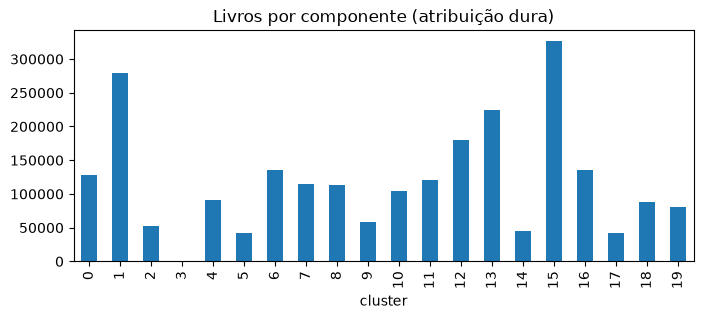

maior componente: 13.8% | menor: 0.0%


In [8]:
prof['livros'].plot.bar(title='Livros por componente (atribuição dura)', figsize=(8, 3)); plt.show()
print('maior componente:', f"{prof['livros'].max() / prof['livros'].sum():.1%}", '| menor:', f"{prof['livros'].min() / prof['livros'].sum():.1%}")

### Artefatos

`book_vectors` (entrada da rede neural): features padronizadas, flags de ausência e probabilidades de componente. `book_meta`: título, autor, popularidade e nota para os exemplos qualitativos.

In [9]:
vec = pd.DataFrame(scaler.transform(feat[GMM_COLS].to_numpy(dtype=float)), index=feat.index, columns=GMM_COLS, dtype='float32')
vec[['year_missing', 'pages_missing']] = feat[['year_missing', 'pages_missing']].astype('float32')
vec = vec.join(book_probs).rename_axis('book_id')
meta = books_df[['book_id', 'title', 'name', 'ratings_count', 'average_rating']].set_index('book_id')

book_probs.to_parquet('book_probs.parquet')
vec.to_parquet('book_vectors.parquet')
meta.to_parquet('book_meta.parquet')
joblib.dump({'scaler': scaler, 'pca': pca, 'gmm': gmm, 'cols': GMM_COLS, 'genres': GENRES}, 'gmm_books.joblib')
print(vec.shape, meta.shape)

(2360655, 36) (2360655, 4)
